https://github.com/mihaniky/AI_Architect_3_1_4_Classification

In [77]:
import numpy as np  # быстрые массивы и векторизованная математика (NUMerical PYthon)
import pandas as pd  # табличные данные (DataFrame, Series) (panel data)
import matplotlib.pyplot as plt  # визуализация: диаграммы и графики (MATLAB plotting library)
import seaborn as sns  # статистическая визуализация поверх Matplotlib

from sqlalchemy import create_engine, text # работа напрямую с SQL
# pip install python-dotenv # (Installer Program)
from dotenv import load_dotenv # работа с файлом .env

import os # operating system

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.pipeline import Pipeline

### 0. Загрузка данных ###

In [120]:
# текст запроса
query = """
    WITH defect_stats AS (
    SELECT
        p.product_id,
        p.product_name,
        dt.defect_type_id,
        dt.defect_name,
        COUNT(*) AS defect_count
    FROM products p
    JOIN production_orders po     ON po.product_id              = p.product_id
    JOIN quality_inspections qi   ON qi.production_operation_id = po.production_order_id
    JOIN quality_defects qd       ON qd.inspection_id           = qi.inspection_id
    JOIN defect_types dt          ON dt.defect_type_id          = qd.defect_type_id
    GROUP BY p.product_id, p.product_name,
             dt.defect_type_id, dt.defect_name
),
ranked_defect AS (
    SELECT
        *,
        ROW_NUMBER() OVER (
            PARTITION BY product_id
            ORDER BY defect_count DESC, defect_type_id
        ) AS rn
    FROM defect_stats
),
top_defect AS (
    SELECT
        product_id,
        defect_name,
        defect_count
    FROM ranked_defect
    WHERE rn = 1
),
employee_work AS (
    SELECT
        p.product_id,
        p.product_name,
        e.employee_id,
        e.first_name || ' ' || e.last_name AS employee_name,
        r.role_name,
        -- Считаем часы работы: (ended_at - started_at) в часах
        SUM(
            EXTRACT(EPOCH FROM (
                COALESCE(moa.ended_at, NOW()) - moa.started_at
            )) / 3600.0
        ) AS hours_worked
    FROM products p
    JOIN production_orders po       ON po.product_id           = p.product_id
    JOIN production_operations pop  ON pop.production_order_id = po.production_order_id
    JOIN machine_operator_assignments moa
         ON moa.machine_id          = pop.machine_id
    JOIN employees e                ON e.employee_id           = moa.employee_id
    LEFT JOIN employee_roles r      ON r.role_id               = e.role_id
    GROUP BY p.product_id, p.product_name,
             e.employee_id, employee_name, r.role_name
),
ranked_employee AS (
    SELECT
        *,
        ROW_NUMBER() OVER (
            PARTITION BY product_id
            ORDER BY hours_worked DESC, employee_id
        ) AS rn
    FROM employee_work
),
top_employee AS (
    SELECT
        product_id,
        employee_name,
        role_name,
        hours_worked
    FROM ranked_employee
    WHERE rn = 1
)
SELECT
    CASE WHEN COALESCE(td.defect_count, 0) > 0 THEN 1 ELSE 0 END AS has_defects,
    so.sales_order_id,
    so.customer_id,
    soi.product_id,
    p.product_name,
    p.standard_production_time_minutes AS prod_minutes,
    p.standard_cost,
    soi.quantity,
    soi.unit_price,
    pc.category_name,
    COALESCE(td.defect_name, '-') AS top_defect_name,
    COALESCE(te.employee_name, '-') AS top_employee_name,
    COALESCE(td.defect_count, 0) AS top_defect_count,
    COALESCE(ROUND(te.hours_worked::numeric, 2), 0) AS top_employee_hours,
    CASE
        WHEN COALESCE(soi.unit_price, 0) = 0
             OR p.standard_cost * 100.0 / soi.unit_price > 70 THEN 1
        ELSE 0
    END AS is_cost_high
FROM sales_orders so
JOIN sales_order_items soi      ON so.sales_order_id = soi.sales_order_id
JOIN products p                 ON soi.product_id    = p.product_id
LEFT JOIN product_categories pc ON p.category_id     = pc.category_id
LEFT JOIN top_defect td         ON td.product_id     = p.product_id
LEFT JOIN top_employee te       ON te.product_id     = p.product_id
ORDER BY so.order_date DESC, so.sales_order_id, soi.sales_order_item_id;
"""

In [121]:
# явки-пароли (r (= real), как есть, обходит слеши)
ENV_PATH = r"C:\Users\nmm\Documents\GitHub\manufacturing.env"
if os.path.exists(ENV_PATH):
    # load_dotenv(ENV_PATH)
    load_dotenv(ENV_PATH, override=True) # использовать перезапись , т.к. не видит изменений (напр. смена БД)
    # print("База данных:", os.getenv('DB_NAME'))
else:
    print("Файл .env не найден")
host = os.getenv("DB_HOST")
database = os.getenv("DB_NAME")
user = os.getenv("DB_USER")
password = os.getenv("DB_PASSWORD")
# port = os.getenv("DB_PORT")

port = 5432
conn_url = f"postgresql://{user}:{password}@{host}:{port}/{database}"
engine = create_engine(conn_url)

try:
    with engine.connect() as conn:
        df = pd.read_sql(query, conn)        
except: 
    port = 5433
    conn_url = f"postgresql://{user}:{password}@{host}:{port}/{database}"
    engine = create_engine(conn_url)
    df = pd.read_sql(query, engine)
print(f" Данные получены через порт {port}")

df.head()

 Данные получены через порт 5432


,has_defects,sales_order_id,customer_id,product_id,product_name,prod_minutes,standard_cost,quantity,unit_price,category_name,top_defect_name,top_employee_name,top_defect_count,top_employee_hours,is_cost_high
0,0,972,69,8,Корпус промышленного контроллера серии ПР-107,110.44,225215.89,168.0,284649.00,Электромеханические изделия,-,Андрей Новиков,0,3115942.30,1
1,1,987,53,13,Электромеханический привод серии ПР-112,125.91,149777.35,388.0,195994.38,Системы управления,Дефект сварного соединения,Андрей Новиков,1,3114951.97,1
2,0,987,53,16,Промышленный контроллер серии ПР-115,135.58,63270.34,260.0,93501.49,Средства автоматизации,-,Максим Попов,0,2480421.14,0
3,0,971,42,8,Корпус промышленного контроллера серии ПР-107,110.44,225215.89,259.0,368391.29,Электромеханические изделия,-,Андрей Новиков,0,3115942.30,0
4,1,977,61,4,Корпус промышленного контроллера серии ПР-103,51.99,84394.81,134.0,104503.27,Средства автоматизации,Ошибка сборки,Андрей Новиков,2,2473103.64,1


### 1. Подготовка данных ###

In [122]:
# target = is_cost_high (затратно/незатратно)
df['target'] = np.where(df["is_cost_high"] == 1, 1, 0)
df.head()

,has_defects,sales_order_id,customer_id,product_id,product_name,prod_minutes,standard_cost,quantity,unit_price,category_name,top_defect_name,top_employee_name,top_defect_count,top_employee_hours,is_cost_high,target
0,0,972,69,8,Корпус промышленного контроллера серии ПР-107,110.44,225215.89,168.0,284649.00,Электромеханические изделия,-,Андрей Новиков,0,3115942.30,1,1
1,1,987,53,13,Электромеханический привод серии ПР-112,125.91,149777.35,388.0,195994.38,Системы управления,Дефект сварного соединения,Андрей Новиков,1,3114951.97,1,1
2,0,987,53,16,Промышленный контроллер серии ПР-115,135.58,63270.34,260.0,93501.49,Средства автоматизации,-,Максим Попов,0,2480421.14,0,0
3,0,971,42,8,Корпус промышленного контроллера серии ПР-107,110.44,225215.89,259.0,368391.29,Электромеханические изделия,-,Андрей Новиков,0,3115942.30,0,0
4,1,977,61,4,Корпус промышленного контроллера серии ПР-103,51.99,84394.81,134.0,104503.27,Средства автоматизации,Ошибка сборки,Андрей Новиков,2,2473103.64,1,1


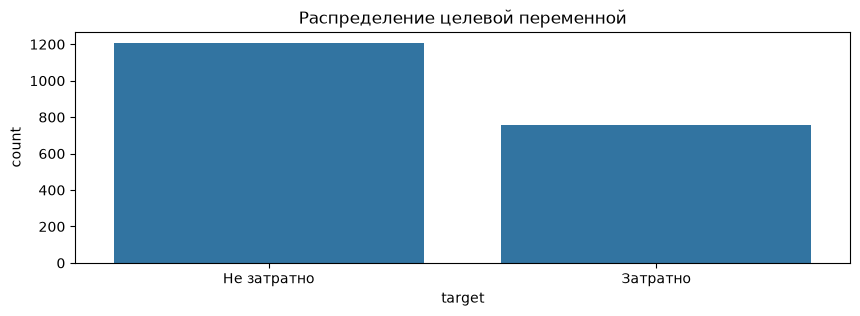

In [81]:
fig, ax = plt.subplots(1,1, figsize = (10,3))
sns.barplot(df['target'].value_counts())
ax.set_title(f'Распределение целевой переменной')
ax.xaxis.set_ticks(range(2))
ax.set_xticklabels(["Не затратно", "Затратно"])
plt.show()

### 2. Изучаем связь целевой переменной и предикторов ###

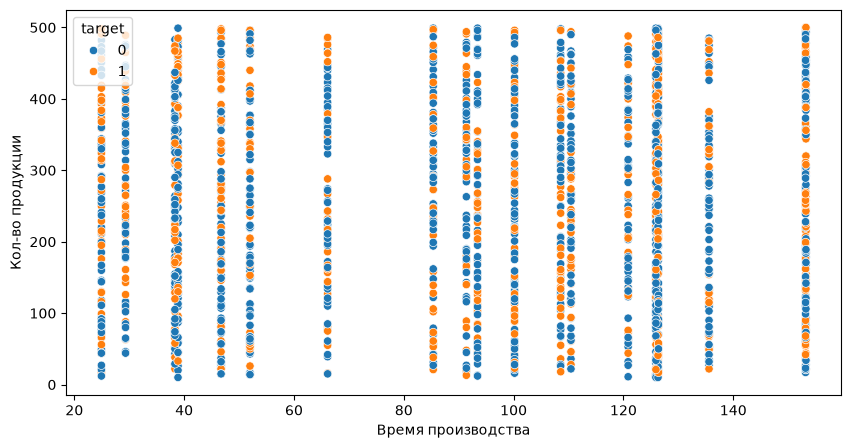

In [116]:
# Потенциальные предикторы:
# standard_cost, unit_price - нельзя т.к. напрямую рассчитывают таргет!
target_col = ["target"]
features_col = ["prod_minutes", "quantity"]
# features_col = ["prod_minutes", "quantity", "top_defect_count", "top_employee_hours"]

fig, ax = plt.subplots(1,1, figsize = (10, 5))
sns.scatterplot(x = "prod_minutes", y = "quantity", data = df, hue = "target", ax = ax)
ax.set_xlabel("Время производства")
ax.set_ylabel("Кол-во продукции")
plt.show()

In [118]:
from scipy.stats import pointbiserialr

features = ["prod_minutes", "quantity", "top_defect_count",
            "top_employee_hours", "standard_cost", "unit_price"]

print("Связь с is_cost_high:\n")
for f in features:
    r, p = pointbiserialr(df["is_cost_high"], df[f])
    sig = "✅" if p < 0.05 else "❌"
    print(f"{f:25s} r = {r:+.4f}  p = {p:.6f}  {sig}")

Связь с is_cost_high:

prod_minutes              r = +0.0057  p = 0.802413  ❌
quantity                  r = +0.0273  p = 0.227327  ❌
top_defect_count          r = -0.0038  p = 0.867523  ❌
top_employee_hours        r = +0.0238  p = 0.292217  ❌
standard_cost             r = +0.0278  p = 0.218016  ❌
unit_price                r = -0.1438  p = 0.000000  ✅


In [119]:
from scipy.stats import spearmanr

for f in ["prod_minutes", "quantity", "top_defect_count",
          "top_employee_hours", "standard_cost", "unit_price"]:
    rho, p = spearmanr(df["is_cost_high"], df[f])
    sig = "✅" if p < 0.05 else "❌"
    print(f"{f:25s} ρ = {rho:+.4f}  p = {p:.6f}  {sig}")

prod_minutes              ρ = +0.0048  p = 0.832238  ❌
quantity                  ρ = +0.0273  p = 0.227185  ❌
top_defect_count          ρ = -0.0035  p = 0.876000  ❌
top_employee_hours        ρ = +0.0257  p = 0.255753  ❌
standard_cost             ρ = +0.0336  p = 0.136493  ❌
unit_price                ρ = -0.1475  p = 0.000000  ✅


### 3. Модель классификации KNN (K-Nearest Neighbors) ###

#### 3.1. Инициализация функций ####

In [104]:
# Делим выборку на обучающую и тестовую
def split_train_test(df, features_col, target_col):
    X = df[features_col]
    y = df[target_col]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.33, random_state = 42)
    return X_train, X_test, y_train, y_test

# Инициализуем и обучаем модель классификации KNN
def train_model(X_train, y_train, n_neighbors=3):
    model = KNeighborsClassifier(n_neighbors)
    model.fit(X_train, y_train)
    return model  

# Делаем предсказания на тестовой выборке
def get_predictions(model, X_test, proba=False):
    if proba:
        return model.predict_proba(X_test)[:, 1] # вероятность класса 1
    else:
        return model.predict(X_test) # класс 0 или 1

def get_prediction_from_proba(y_proba, threshold=0.5):
    return (y_proba > threshold)*1
    
# Визуализуем предсказание на тестовой выборке
def visualize_prediction(y_true, y_pred, model):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot()
    plt.show()

# Считаем метрики качества на тестовой выборке
def show_metrics(y_true, y_pred):
    #               Предсказано 0	Предсказано 1
    # Реально 0	TN (True Negative)	FP (False Positive)
    # Реально 1	FN (False Negative)	TP (True Positive)
    print('Среднее значение Y: ', np.mean(y_true))
    print('Accuracy: ', accuracy_score(y_true, y_pred))
    # Accuracy = (TP+TN)/(TP+TN+FP+FN) «доля правильных ответов»
    print('Precision: ', precision_score(y_true, y_pred))
    # Precision = TP/(TP+FP) «точность» / «качество попаданий»
    print('Recall: ', recall_score(y_true, y_pred))
    # Recall = TP/(TP+FN) «полнота» / «чувствительность»
    print('F1: ', f1_score(y_true, y_pred))
    # F1 = 2*(Precision*Recall/Precision+Recall) «среднее гармоническое» / «баланс»
    print('ROC-AUC: ', roc_auc_score(y_true, y_pred))
    # TPR = TP/(TP+FN)
    # FPR = FP/(FP+TN)
    # ROC-кривая — график зависимости TPR (Recall) от FPR
    # AUC = площадь под этой кривой 

#### 3.2. Обучение, предсказание и визуализация модели ####

#### 3.2.1. Простая модель KNN с двумя предикторами без масштабирования ####

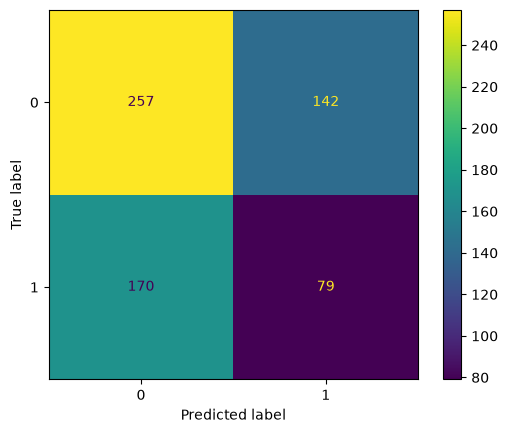

Среднее значение Y:  0.38425925925925924
Accuracy:  0.5185185185185185
Precision:  0.3574660633484163
Recall:  0.3172690763052209
F1:  0.33617021276595743
ROC-AUC:  0.48068967599722195


In [112]:
X_train, X_test, y_train, y_test = split_train_test(df, features_col, target_col)
model = train_model(X_train, y_train.values.ravel())
y_pred = get_predictions(model, X_test)
visualize_prediction(y_test, y_pred, model)
show_metrics(y_test, y_pred)
# .values	превращает в numpy-массив формы (n, 1)
# .ravel()	выпрямляет в 1D-массив формы (n,)

#### 3.2.2. Простая модель KNN с двумя предикторами с масштабированием ####

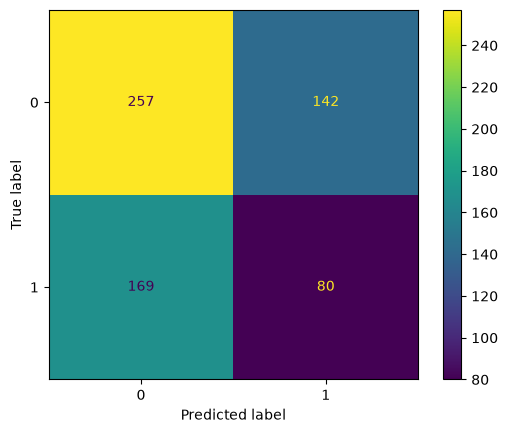

Среднее значение Y:  0.38425925925925924
Accuracy:  0.5200617283950617
Precision:  0.36036036036036034
Recall:  0.321285140562249
F1:  0.33970276008492567
ROC-AUC:  0.48269770812573604


In [113]:
X_train, X_test, y_train, y_test = split_train_test(df, features_col, target_col)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model = train_model(X_train_scaled, y_train.values.ravel())
y_pred = get_predictions(model, X_test_scaled)
visualize_prediction(y_test, y_pred, model)
show_metrics(y_test, y_pred)

#### 3.2.3. Простая модель KNN с двумя предикторами c масштабированием и N = 5 ####

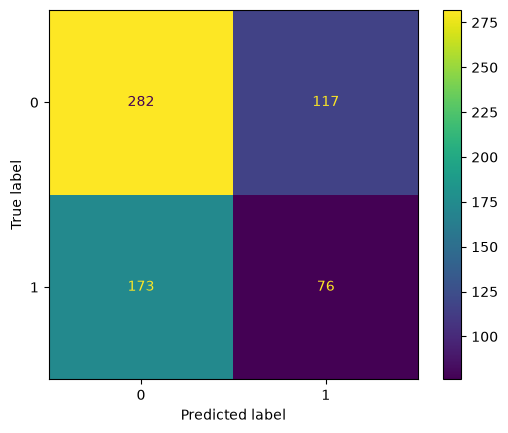

Среднее значение Y:  0.38425925925925924
Accuracy:  0.5524691358024691
Precision:  0.39378238341968913
Recall:  0.30522088353413657
F1:  0.3438914027149321
ROC-AUC:  0.5059939004136849


In [114]:
X_train, X_test, y_train, y_test = split_train_test(df, features_col, target_col)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model = train_model(X_train_scaled, y_train.values.ravel(), n_neighbors=5)
y_pred = get_predictions(model, X_test_scaled)
visualize_prediction(y_test, y_pred, model)
show_metrics(y_test, y_pred)

#### 3.2.4. Простая модель KNN с двумя предикторами c масштабированием, N = 5 и изменяемым значением порога ####

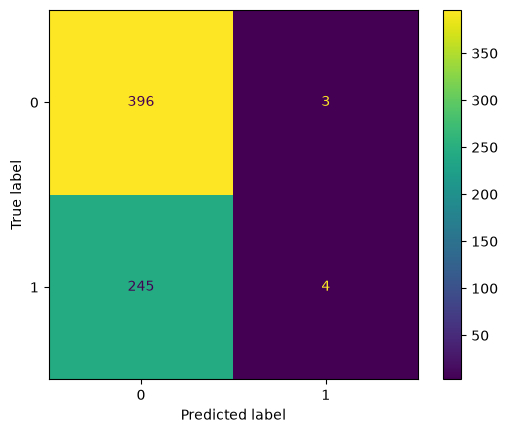

Среднее значение Y:  0.38425925925925924
Accuracy:  0.6172839506172839
Precision:  0.5714285714285714
Recall:  0.01606425702811245
F1:  0.03125
ROC-AUC:  0.5042727300178156


In [115]:
X_train, X_test, y_train, y_test = split_train_test(df, features_col, target_col)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model = train_model(X_train_scaled, y_train.values.ravel(), n_neighbors=5)
y_proba = get_predictions(model, X_test_scaled, proba = True)
y_pred = get_prediction_from_proba(y_proba, threshold = 0.8)
visualize_prediction(y_test, y_pred, model)
show_metrics(y_test, y_pred)

**Вывод:** Модель не различает классы

- Accuracy = 53% правильных
- Precision = 37% прогнозов «1» верны
- Recall = 32% реальных «1»
- F1 = 0.341
- ROC-AUC = 0.489	< 0.5 => хуже случайного